# Recommandations marketing pour le segment Decel

Ce notebook chiffre les leviers d'action identifiés dans `Analyse_Decel.ipynb` et `Migration.ipynb`, puis propose un plan d'action priorisé et mesurable.

**Rappel du diagnostic :**
- 806 clientes, 7 % du CA, 283 € par cliente et par an ; le panier moyen le plus élevé des clientes fidèles.
- 70 % ont fait leur dernier achat entre janvier et mars 2016 : elles étaient actives peu avant de devenir Decel.
- Profil A (479) : actives au printemps-été 2015, sans achat depuis avril 2016 (ce qui découle aussi de la définition du segment). Profil B (327) : sans achat au printemps-été 2015.
- Moins d'adoption du bain avant la période (41 % contre 53 % pour les Good et 59 % pour les Top) et, dans une moindre mesure, du homewear (42 % contre 46 % et 55 %).
- Pas de profil socio-démographique distinctif : le ciblage doit reposer sur les achats.
- Statut transitoire : un an plus tard, environ un tiers remonte en Top/Good et un tiers devient inactif.

**Lien avec le contexte de Feminiz** : la marque a **élargi sa gamme** (bain, homewear) et lancé un **programme de fidélité**. Les recommandations s'appuient sur ces deux atouts : la carte de fidélité permet d'identifier et de contacter les Decel, et les nouvelles gammes sont moins adoptées par les Decel que par les Top/Good (nettement pour le bain, plus légèrement pour le homewear).

Ce notebook ré-exécute `Migration.ipynb`, qui ré-exécute lui-même le notebook principal.

In [1]:
%%capture
%run Migration.ipynb

In [2]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

SEG = MASTER_RFM[['ID_INDIVIDU', 'RFM_SEG']]
R = RECEIPTS_INFO_RFM.merge(SEG, on = 'ID_INDIVIDU')
R['MONTH'] = R['DATE_ACHAT'].dt.month
DEC = MASTER_RFM[MASTER_RFM['RFM_SEG'] == '3 Decel'].copy()
summer15 = set(RECEIPTS_INFO_OK.loc[
    (RECEIPTS_INFO_OK['DATE_ACHAT'] >= '2015-04-01') & (RECEIPTS_INFO_OK['DATE_ACHAT'] < '2015-09-01'), 'ID_INDIVIDU'])
DEC['PROFIL'] = np.where(DEC['ID_INDIVIDU'].isin(summer15), 'A', 'B')
print(DEC['PROFIL'].value_counts())

PROFIL
A    479
B    327
Name: count, dtype: int64


## 1. Levier « récompense » : rester cohérent avec le positionnement de la marque

On regarde le recours aux remises et aux cadeaux (articles à prix nul) par segment, **sur les mêmes mois (sept.→mars)** pour que la comparaison ne dépende pas de la saison.

In [3]:
paid = R[R['PRICE'] > 0].copy()
paid['REMISE'] = (paid['REMISE_PCT'] > 0) & (paid['REMISE_PCT'] < 100)
AH = [9, 10, 11, 12, 1, 2, 3]
REWARD = pd.DataFrame({
    'Articles payants remisés, sept.-mars (%)': paid[paid['MONTH'].isin(AH)].groupby('RFM_SEG')['REMISE'].mean() * 100,
    'Cadeaux par visite': MASTER_RFM.groupby('RFM_SEG')['NB_GIFTS'].sum() / MASTER_RFM.groupby('RFM_SEG')['NB_VISITS'].sum(),
    'Panier moyen sept.-mars (€)': VISIT_VALUE.merge(SEG, on = 'ID_INDIVIDU')
        .loc[lambda v: v['DATE_ACHAT'].dt.month.isin(AH)]
        .groupby('RFM_SEG')['MONETARY_VALUE'].mean(),
}).reindex(SEG_ORDER)
REWARD.round(2)

,"Articles payants remisés, sept.-mars (%)",Cadeaux par visite,Panier moyen sept.-mars (€)
RFM_SEG,,,
5 Top,0.34,0.71,93.21
4 Good,0.10,0.73,98.28
3 Decel,0.18,0.67,104.35
2 Small,0.00,0.26,49.92
1 Weak,0.07,0.37,89.66
New,0.23,0.80,138.69


**Lecture :**
- La marque ne pratique **presque pas de remises**, pour tous les segments (moins de 0,4 % des articles payants). On ne peut donc **pas** mesurer comment les clientes réagiraient à une remise : les données ne tranchent pas.
- Les **cadeaux** sont en revanche un mécanisme courant du programme de fidélité (≈ 0,7 par visite), au même niveau pour les Decel que pour les Top : ils ne distinguent pas les Decel, mais ils font partie des habitudes de la marque.
- À saison égale, les Decel ont **le panier le plus élevé des clientes fidèles** (≈ 104 € contre 98 € pour les Good et 93 € pour les Top).

→ **Recommandation de positionnement (et non conclusion des données)** : ne pas réactiver par la remise, qui serait nouvelle pour la marque et risquerait d'habituer les clientes à attendre une promotion (étude de cas du cours, slides 47-48). Utiliser les leviers déjà en place : **cadeau avec achat** (idéalement conditionné, par exemple à l'achat d'un maillot, pour limiter l'effet d'aubaine) et **services** (avant-première, essayage).

## 2. Levier « boutique » : la vendeuse comme canal de réactivation

In [4]:
base_share = MASTER_RFM.loc[MASTER_RFM['RFM_SEG'] != 'New', 'SHARE_MANAGING_STORE'].mean()
print(f"Part moyenne des visites dans la boutique de rattachement : Decel {100 * DEC['SHARE_MANAGING_STORE'].mean():.0f} % (base hors New : {100 * base_share:.0f} %)")
print(f"Decel faisant au moins la moitié de leurs visites dans leur boutique : {100 * (DEC['SHARE_MANAGING_STORE'] >= 0.5).mean():.0f} %")

PER_STORE = DEC['MANAGING_STORE'].value_counts()
print(f"{PER_STORE.size} boutiques de rattachement, {PER_STORE.mean():.1f} Decel par boutique en moyenne (médiane {PER_STORE.median():.0f}, max {PER_STORE.max()})")
print(f"Les 20 premières boutiques concentrent {100 * PER_STORE.head(20).sum() / PER_STORE.sum():.0f} % des Decel")

TOP_STORES = (
    PER_STORE.head(10).rename('Decel').to_frame()
    .merge(STORE.set_index('CODE_BOUTIQUE')[['VILLE', 'REGIONS', 'CENTRE_VILLE']], left_index = True, right_index = True, how = 'left')
)
TOP_STORES

Part moyenne des visites dans la boutique de rattachement : Decel 64 % (base hors New : 62 %)
Decel faisant au moins la moitié de leurs visites dans leur boutique : 69 %
87 boutiques de rattachement, 9.3 Decel par boutique en moyenne (médiane 8, max 28)
Les 20 premières boutiques concentrent 43 % des Decel


,Decel,VILLE,REGIONS,CENTRE_VILLE
MANAGING_STORE,,,,
753,28,GUICHARD,Paris,Centre ville
131,28,AIX EN PROVENCE,Province,Centre ville
591,22,VILLENEUVE D'ASCQ,Province,Centre Commercial
920,22,LA DEFENSE,Paris,Centre Commercial
7511,20,BONAPARTE,Paris,Centre ville
921,20,BOULOGNE,Paris,Centre ville
130,19,MARSEILLE,Province,Centre ville
693,18,LYON HERRIOT,Province,Centre ville
7516,16,COMMERCE 2,Paris,Centre ville


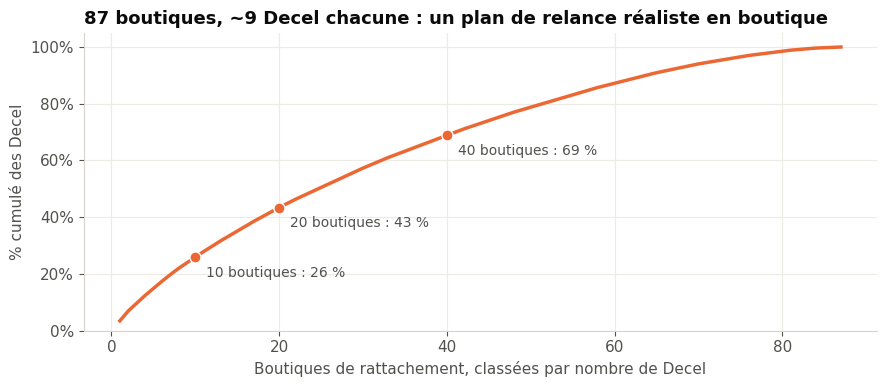

In [5]:
cum = PER_STORE.cumsum() / PER_STORE.sum() * 100
fig, ax = plt.subplots(figsize = (9, 4))
ax.plot(range(1, len(cum) + 1), cum.values, color = DECEL, lw = 2.5)
for k in [10, 20, 40]:
    ax.plot(k, cum.iloc[k - 1], 'o', color = DECEL, ms = 8, markeredgecolor = 'white')
    ax.annotate(f'{k} boutiques : {cum.iloc[k - 1]:.0f} %', (k, cum.iloc[k - 1]), textcoords = 'offset points',
                xytext = (8, -14), color = INK2, fontsize = 10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
ax.set_ylim(0, 105)
ax.set_xlabel('Boutiques de rattachement, classées par nombre de Decel')
ax.set_ylabel('% cumulé des Decel')
ax.set_title(f"{len(PER_STORE)} boutiques, ~{PER_STORE.mean():.0f} Decel chacune : un plan de relance réaliste en boutique")
fig.tight_layout()
save(fig, '11_decel_par_boutique')

**Lecture :** comme le reste de la base (62 %), les Decel font l'essentiel de leurs visites dans **leur** boutique (64 %). Ce n'est pas un trait propre au segment, mais c'est un **atout opérationnel** : avec environ 9 Decel par boutique, chaque équipe peut **contacter personnellement** ses clientes (appel, SMS, invitation), ce qui correspond à la relation de conseil propre à la lingerie. Les 20 premières boutiques couvrent 43 % du segment : elles peuvent servir de **pilote**.

## 3. Levier « produit » : les nouvelles gammes comme raison de revenir

In [6]:
ci = CUSTOMERS_INFO.set_index('ID_INDIVIDU')
known = ci.loc[DEC['ID_INDIVIDU'], ['TAILLE', 'TAILLE_SG', 'TAILLE_BONNET']].notna().all(axis = 1)
print(f"Decel dont la taille complète (taille, tour de poitrine, bonnet) est connue : {100 * known.mean():.0f} %")

# Achat de bain mesuré AVANT avril 2015, donc sans l'été 2015 qui définit les profils A et B
hist = RECEIPTS_INFO_OK[RECEIPTS_INFO_OK['DATE_ACHAT'] < '2015-04-01']
ever_bain = set(hist.loc[hist['Ligne'] == 'Bain', 'ID_INDIVIDU'])
has_hist = set(hist['ID_INDIVIDU'])
sub = DEC[DEC['ID_INDIVIDU'].isin(has_hist)].copy()
sub['DEJA_BAIN'] = sub['ID_INDIVIDU'].isin(ever_bain)
print(sub.groupby('PROFIL')['DEJA_BAIN'].agg(['size', 'mean']).assign(mean = lambda d: (100 * d['mean']).round(0))
      .rename(columns = {'size': 'clientes avec historique', 'mean': '% bain acheté avant avril 2015'}))

ah = R['MONTH'].isin([9, 10, 11, 12, 1, 2, 3])
home = R['Ligne'] == 'Homewear'
print(f"Part du CA réalisée de septembre à mars : homewear {100 * R.loc[home & ah, 'PRICE'].sum() / R.loc[home, 'PRICE'].sum():.1f} %, "
      f"ensemble du CA {100 * R.loc[ah, 'PRICE'].sum() / R['PRICE'].sum():.1f} %")

Decel dont la taille complète (taille, tour de poitrine, bonnet) est connue : 61 %
        clientes avec historique  % bain acheté avant avril 2015
PROFIL                                                          
A                            379                            31.0
B                            302                            25.0
Part du CA réalisée de septembre à mars : homewear 73.5 %, ensemble du CA 53.9 %


**Lecture :**
- **Bain** : c'est la gamme que les Decel ont le moins adoptée (41 % avant sept. 2015, contre 53 % pour les Good et 59 % pour les Top). Mesuré sans l'été 2015 (qui définit les profils), l'écart entre profils est modeste : 31 % du profil A contre 25 % du profil B avaient déjà acheté du bain. Pour les deux profils, le bain est **une raison de revenir au printemps**, avant l'été.
- **Homewear** : l'écart est plus faible (42 % contre 46 % pour les Good et 55 % pour les Top). Le homewear se vend surtout en automne-hiver (≈ 74 % de son CA de septembre à mars, contre ≈ 54 % pour l'ensemble du CA), la saison où les Decel sont actives : c'est un **levier de vente croisée à la rentrée**.
- La taille complète de **61 %** des Decel est connue : on peut proposer **une sélection de maillots à leur taille**, ce qui rend le message personnel et utile.

## 4. Levier « prévention » : une alerte avant la bascule en Decel

Idée : relancer une bonne cliente (FM moyen ou élevé) qui n'a pas racheté depuis un certain temps, **avant** qu'elle ne devienne Decel.

**Validation sur l'année précédente (backtest)** : on prend les clientes Good et Top de 2014-15, on les classe selon leur récence au 31/08/2015 et on regarde ce qu'elles sont devenues en 2015-16 (période disjointe, pas de fuite d'information).

In [7]:
n1 = SEG_N1[SEG_N1['RFM_SEG'].isin(['5 Top', '4 Good'])][['ID_INDIVIDU', 'RFM_SEG', 'RECENCY']].copy()
n1['RECENCE_N-1'] = pd.cut(n1['RECENCY'], [-1, 30, 60, 90, 120, 150], labels = ['0-30 j', '31-60 j', '61-90 j', '91-120 j', '121-150 j'])
n1['SEGMENT_N'] = n1['ID_INDIVIDU'].map(MIG['N'])
BACKTEST = n1.groupby('RECENCE_N-1', observed = True).agg(
    clientes = ('ID_INDIVIDU', 'size'),
    **{'Decel ou inactive en N (%)': ('SEGMENT_N', lambda s: s.isin(['3 Decel', 'Inactive']).mean() * 100),
       'Top/Good en N (%)': ('SEGMENT_N', lambda s: s.isin(['5 Top', '4 Good']).mean() * 100)},
)
above = n1['RECENCY'] > 90
print(f"Risque (Decel ou inactive en N) : {100 * n1.loc[above, 'SEGMENT_N'].isin(['3 Decel', 'Inactive']).mean():.0f} % au-delà de 90 j, "
      f"{100 * n1.loc[~above, 'SEGMENT_N'].isin(['3 Decel', 'Inactive']).mean():.0f} % en dessous")
BACKTEST.round(1)

Risque (Decel ou inactive en N) : 31 % au-delà de 90 j, 24 % en dessous


,clientes,Decel ou inactive en N (%),Top/Good en N (%)
RECENCE_N-1,,,
0-30 j,544,20.4,59.2
31-60 j,850,24.6,55.4
61-90 j,737,24.8,53.2
91-120 j,445,30.3,47.9
121-150 j,263,31.6,41.8


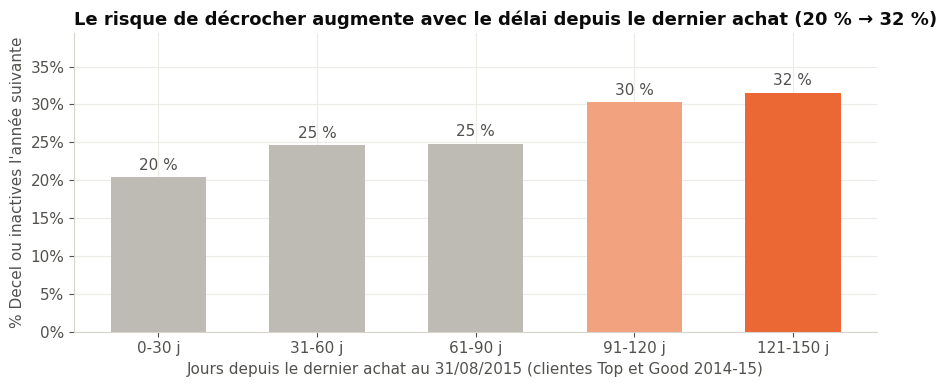

In [8]:
fig, ax = plt.subplots(figsize = (9, 4))
colors = [OTHER, OTHER, OTHER, '#f2a27e', DECEL]
bars = ax.bar([str(i) for i in BACKTEST.index], BACKTEST['Decel ou inactive en N (%)'], color = colors, width = 0.6)
ax.bar_label(bars, fmt = '%.0f %%', padding = 3, color = INK2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
ax.set_ylim(0, BACKTEST['Decel ou inactive en N (%)'].max() * 1.25)
ax.set_xlabel('Jours depuis le dernier achat au 31/08/2015 (clientes Top et Good 2014-15)')
ax.set_ylabel("% Decel ou inactives l'année suivante")
ax.set_title("Le risque de décrocher augmente avec le délai depuis le dernier achat (20 % → 32 %)")
fig.tight_layout()
save(fig, '12_backtest_alerte')

In [9]:
# Vivier actuel : Good 2015-16 selon le délai depuis le dernier achat au 31/08/2016
good = MASTER_RFM[MASTER_RFM['RFM_SEG'] == '4 Good']
POOL = pd.cut(good['RECENCY'], [60, 90, 120, 150]).value_counts().sort_index()
print(POOL)
print(f"Good au-delà de 90 jours : {POOL.iloc[1:].sum()} sur {len(good)} ({100 * POOL.iloc[1:].sum() / len(good):.0f} %)")

RECENCY
(60, 90]      762
(90, 120]     450
(120, 150]    372
Name: count, dtype: int64
Good au-delà de 90 jours : 822 sur 1584 (52 %)


**Lecture :** le risque de décrocher augmente progressivement avec le délai depuis le dernier achat, de 20 % à 32 %. Mais une alerte reste un **signal faible** : au-delà de 90 jours, environ **3 clientes sur 10** décrochent réellement l'année suivante (contre environ 1 sur 4 en dessous), et 822 des 1 584 Good (52 %) dépassent déjà ce seuil. Il faut donc **graduer** :
- **121-150 jours (372 Good)** : priorité, contact personnel par la boutique ;
- **91-120 jours (450 Good)** : relance légère et peu coûteuse (e-mail, SMS).

*Ce backtest montre une association, pas l'efficacité d'une alerte : seule la mesure contre un groupe témoin (section 5) le dira.*

## 5. Mesurer l'effet : un test A/B avec groupe témoin

Sans groupe témoin, impossible de savoir si une Decel revient grâce à la campagne ou d'elle-même. **Indicateur principal** : le réachat (achat payant) dans les 8 semaines suivant le contact. On mesure son niveau « naturel » sur les Decel de l'année précédente.

In [10]:
dec_n1 = set(SEG_N1.loc[SEG_N1['RFM_SEG'] == '3 Decel', 'ID_INDIVIDU'])
def rebuy_rate(start, end):
    # achat payant uniquement (les cadeaux seuls ne comptent pas comme un réachat)
    ids = set(RECEIPTS_INFO_OK.loc[(RECEIPTS_INFO_OK['DATE_ACHAT'] >= start) & (RECEIPTS_INFO_OK['DATE_ACHAT'] <= end)
                                   & (RECEIPTS_INFO_OK['PRICE'] > 0), 'ID_INDIVIDU'])
    return len(dec_n1 & ids) / len(dec_n1)

BASE_RENTREE = rebuy_rate('2015-09-01', '2015-10-26')
BASE_PRINTEMPS = rebuy_rate('2016-03-01', '2016-04-25')
BASE_8W = (BASE_RENTREE + BASE_PRINTEMPS) / 2
print(f"Decel 2014-15 ayant racheté en 8 semaines : rentrée {100 * BASE_RENTREE:.1f} %, printemps {100 * BASE_PRINTEMPS:.1f} %")
print(f"Taux de réachat « naturel » retenu : {100 * BASE_8W:.1f} %")

Decel 2014-15 ayant racheté en 8 semaines : rentrée 20.2 %, printemps 20.1 %
Taux de réachat « naturel » retenu : 20.2 %


In [11]:
power = NormalIndPower()

def mde(n_test, n_ctrl, base, alternative = 'two-sided'):
    for uplift in np.arange(0.005, 0.40, 0.005):
        es = proportion_effectsize(base + uplift, base)
        if power.power(effect_size = es, nobs1 = n_test, ratio = n_ctrl / n_test, alpha = 0.05, alternative = alternative) >= 0.8:
            return round(100 * uplift, 1)

rows = []
groups = {'Tous les Decel': len(DEC), 'Profil A': (DEC['PROFIL'] == 'A').sum(), 'Profil B': (DEC['PROFIL'] == 'B').sum()}
for name, n in groups.items():
    for share_ctrl in [0.2, 0.3, 0.5]:
        n_ctrl = int(n * share_ctrl)
        rows.append({'Population': name, 'Témoin (%)': int(share_ctrl * 100), 'Testées': n - n_ctrl, 'Témoin': n_ctrl,
                     'Hausse min. détectable, réachat 8 sem. (pts)': mde(n - n_ctrl, n_ctrl, BASE_8W)})
MDE = pd.DataFrame(rows)

# Et si la mesure ne portait que sur les 20 boutiques pilotes ?
pilot_stores = PER_STORE.head(20).index
pilot = DEC[DEC['MANAGING_STORE'].isin(pilot_stores)]
for name, n in {'Pilote 20 boutiques (tous)': len(pilot), 'Pilote 20 boutiques (profil A)': (pilot['PROFIL'] == 'A').sum()}.items():
    n_ctrl = int(n * 0.3)
    print(f"{name} : {n} clientes → hausse min. détectable avec 30 % de témoin : {mde(n - n_ctrl, n_ctrl, BASE_8W)} pts")
MDE

Pilote 20 boutiques (tous) : 350 clientes → hausse min. détectable avec 30 % de témoin : 14.5 pts
Pilote 20 boutiques (profil A) : 206 clientes → hausse min. détectable avec 30 % de témoin : 19.5 pts


,Population,Témoin (%),Testées,Témoin,"Hausse min. détectable, réachat 8 sem. (pts)"
0,Tous les Decel,20,645,161,11.0
1,Tous les Decel,30,565,241,9.5
2,Tous les Decel,50,403,403,8.5
3,Profil A,20,384,95,14.5
4,Profil A,30,336,143,12.5
5,Profil A,50,240,239,11.5
6,Profil B,20,262,65,17.5
7,Profil B,30,229,98,15.0
8,Profil B,50,164,163,14.0


*Test bilatéral, risque 5 %, puissance 80 %.*

**Lecture :** avec 806 clientes, on ne détecte qu'un effet assez fort : environ **9,5 points** de réachat en plus (sur une base d’environ 20 %) avec un témoin de 30 % sur tout le segment, et **12,5 à 15 points** si l'on mesure chaque profil séparément (échantillons plus petits). Restreinte aux 20 boutiques pilotes (≈ 350 Decel), la mesure ne détecterait qu'un effet d'environ 15 points (≈ 20 points pour le seul profil A), ce qui est irréaliste.

**Recommandation :**
- **mesurer sur tout le segment** (toutes les boutiques) : contact digital pour toutes les clientes testées, témoin de 30 %, et **cumul de deux vagues** (rentrée puis printemps) pour gagner en puissance ;
- utiliser les **20 boutiques pilotes** pour tester en plus l'**appel de la vendeuse** : faisabilité, retours des équipes, premiers résultats indicatifs, sans prétendre y mesurer un effet significatif ;
- indicateur secondaire : passage en Top/Good l'année suivante.

## 6. Scénarios économiques (ordres de grandeur)

**Hypothèses explicites** (à affiner avec le marketing) :
- 70 % des Decel contactées, 30 % en témoin ;
- sans campagne, une part des contactées rachète quand même (taux naturel mesuré ci-dessus) ;
- **toute cliente contactée qui rachète reçoit le cadeau** (≈ 10 € de coût), y compris celles qui seraient revenues d'elles-mêmes (**effet d'aubaine**) ;
- coût de contact : 1 € (e-mail/SMS/courrier) ou 4 € (appel de la vendeuse, temps compris) ;
- une cliente réactivée fait au moins une visite au panier moyen des Decel.

In [12]:
panier = DEC['AVG_VISIT_VALUE'].mean()
ca_good = MASTER_RFM.loc[MASTER_RFM['RFM_SEG'] == '4 Good', 'CUMUL_VALUE'].mean()
N_TOTAL = len(DEC)
n_contact = int(N_TOTAL * 0.7)
GIFT = 10
rows = []
for cost_contact, canal in [(1, 'Digital (1 €)'), (4, 'Appel vendeuse (4 €)')]:
    for uplift in [0.05, 0.10, 0.15]:
        extra = n_contact * uplift
        buyers = n_contact * (BASE_8W + uplift)
        cout = n_contact * cost_contact + buyers * GIFT
        ca_incr = extra * panier
        rows.append({
            'Canal': canal,
            'Hausse du réachat (pts)': int(uplift * 100),
            'Réactivées en plus': round(extra),
            'Clientes recevant le cadeau': round(buyers),
            'CA incrémental, 1 visite (€)': round(ca_incr),
            'Coût total (€)': round(cout),
            'CA incrémental / coût': round(ca_incr / cout, 1),
            'Plafond CA annuel si niveau Good (€)': round(extra * ca_good),
        })
SCEN = pd.DataFrame(rows)
print(f"Contactées : {n_contact} | réachat naturel : {100 * BASE_8W:.0f} % | panier moyen Decel : {panier:.0f} € | CA annuel moyen Good : {ca_good:.0f} €")
SCEN

Contactées : 564 | réachat naturel : 20 % | panier moyen Decel : 117 € | CA annuel moyen Good : 374 €


,Canal,Hausse du réachat (pts),Réactivées en plus,Clientes recevant le cadeau,"CA incrémental, 1 visite (€)",Coût total (€),CA incrémental / coût,Plafond CA annuel si niveau Good (€)
0,Digital (1 €),5,28,142,3311,1983,1.7,10561
1,Digital (1 €),10,56,170,6622,2265,2.9,21122
2,Digital (1 €),15,85,198,9934,2547,3.9,31683
3,Appel vendeuse (4 €),5,28,142,3311,3675,0.9,10561
4,Appel vendeuse (4 €),10,56,170,6622,3957,1.7,21122
5,Appel vendeuse (4 €),15,85,198,9934,4239,2.3,31683


**Lecture :**
- En comptant l'effet d'aubaine, la campagne ne devient clairement intéressante qu'à partir d'environ **+10 points** de réachat. À +5 points, le CA incrémental ne représente que 1,7 fois le coût en contact digital, et 0,9 fois avec l'appel de la vendeuse ; comme il s'agit de **CA, pas de marge** (marge non disponible), ce scénario n'est probablement **pas rentable**. À +10 points, le rapport monte à 2,9 (digital) et 1,7 (appel).
- Deux façons d'améliorer le rapport : **conditionner le cadeau** (par exemple à l'achat d'un maillot ou à un panier minimum) pour limiter l'aubaine, et **réserver l'appel de la vendeuse** aux clientes les plus précieuses (profil A, Good à 121-150 jours).
- La colonne « plafond » suppose que chaque réactivée retrouve le niveau d'une Good toute l'année, sans compter ce qu'elle aurait dépensé de toute façon : c'est un **maximum**, pas une prévision. Pour comparaison, le CA printemps-été 2015 du profil A (≈ 82 k€) donne le plafond récupérable sur une saison.

→ C'est précisément pourquoi le **pilote avec groupe témoin** est la première étape : il mesurera l'effet réel avant de généraliser.

## 7. Plan d'action priorisé

In [13]:
PLAN = pd.DataFrame([
    ['P1 (pilote)', 'Rentrée « bon retour »', 'Tous les Decel, dès leur identification au 31/08', 'Sept.-oct.',
     'Invitation à découvrir la collection automne ; mise en avant du homewear (adoption 42 % vs 55 % chez les Top)',
     'E-mail/SMS (toutes boutiques)', 'Réachat payant sous 8 semaines vs témoin'],
    ['P1 (pilote)', 'Relance de printemps', 'Profil A (479)', 'Mars-avril',
     'Invitation en boutique : collection printemps-été et sélection de maillots à sa taille ; cadeau conditionné à un achat',
     'E-mail/SMS (toutes boutiques) + appel de la vendeuse dans 20 boutiques pilotes', 'Réachat payant sous 8 semaines vs témoin ; passage en Top/Good'],
    ['P2', 'Alerte « pré-Decel » graduée', 'Good sans achat depuis 121-150 j (372), puis 91-120 j (450)', 'En continu',
     'Contact personnel pour les 121-150 j ; relance légère pour les 91-120 j',
     'CRM + boutique', 'Part des alertées qui rachètent avant 150 j vs témoin'],
    ['P3', 'Découverte de la gamme bain', 'Profil B (327)', 'Avril-juin',
     'Essayage bain sur rendez-vous, conseil taille (61 % des tailles connues)',
     'Courrier/e-mail + boutique', "Taux d'achat bain"],
    ['Transversal', 'Récompenses sans remise', 'Tous les Decel', "Toute l'année",
     'Cadeau avec achat, avant-premières, soirées privées via le programme de fidélité',
     'Programme de fidélité', 'Panier moyen maintenu'],
    ['Prérequis', 'Mesure et pilotage', 'Tous les Decel', 'Chaque trimestre',
     'Groupe témoin 30 %, historique des contacts, RFM recalculé chaque trimestre',
     'Équipe data / CRM', 'Écart vs témoin ; part des Decel inactives en N+1'],
], columns = ['Priorité', 'Action', 'Cible', 'Quand', 'Contenu', 'Canal', 'Indicateur de succès'])
PLAN

,Priorité,Action,Cible,Quand,Contenu,Canal,Indicateur de succès
0,P1 (pilote),Rentrée « bon retour »,"Tous les Decel, dès leur identification au 31/08",Sept.-oct.,Invitation à découvrir la collection automne ;...,E-mail/SMS (toutes boutiques),Réachat payant sous 8 semaines vs témoin
1,P1 (pilote),Relance de printemps,Profil A (479),Mars-avril,Invitation en boutique : collection printemps-...,E-mail/SMS (toutes boutiques) + appel de la ve...,Réachat payant sous 8 semaines vs témoin ; pas...
2,P2,Alerte « pré-Decel » graduée,"Good sans achat depuis 121-150 j (372), puis 9...",En continu,Contact personnel pour les 121-150 j ; relance...,CRM + boutique,Part des alertées qui rachètent avant 150 j vs...
3,P3,Découverte de la gamme bain,Profil B (327),Avril-juin,"Essayage bain sur rendez-vous, conseil taille ...",Courrier/e-mail + boutique,Taux d'achat bain
4,Transversal,Récompenses sans remise,Tous les Decel,Toute l'année,"Cadeau avec achat, avant-premières, soirées pr...",Programme de fidélité,Panier moyen maintenu
5,Prérequis,Mesure et pilotage,Tous les Decel,Chaque trimestre,"Groupe témoin 30 %, historique des contacts, R...",Équipe data / CRM,Écart vs témoin ; part des Decel inactives en N+1


**Pourquoi cet ordre :**
- **P1** : les deux moments où les Decel sont le plus susceptibles de revenir. À la rentrée, elles entrent dans leur saison d'achat habituelle (automne-hiver) ; au printemps, c'est la saison qu'elles ont manquée. La mesure porte sur **tout le segment** (seule façon de détecter un effet réaliste) ; l'**appel de la vendeuse**, plus coûteux, est d'abord testé dans **20 boutiques pilotes** (43 % du segment) avant d'être généralisé si les retours sont bons.
- **P2** : l'alerte agit en amont, sur un vivier bien plus grand que les Decel, mais avec un signal faible ; elle doit rester peu coûteuse sauf pour les clientes les plus à risque.
- **P3** : le profil B, moins engagé l'été, est une cible de plus long terme pour la gamme bain.

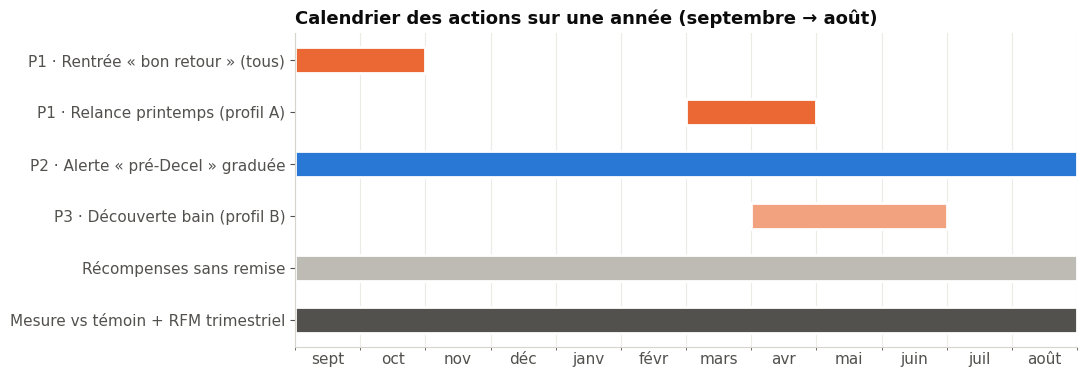

In [14]:
MONTHS = ['sept', 'oct', 'nov', 'déc', 'janv', 'févr', 'mars', 'avr', 'mai', 'juin', 'juil', 'août']
TIMELINE = [
    ('P1 · Rentrée « bon retour » (tous)', 0, 2, DECEL),
    ('P1 · Relance printemps (profil A)', 6, 8, DECEL),
    ('P2 · Alerte « pré-Decel » graduée', 0, 12, COMP),
    ('P3 · Découverte bain (profil B)', 7, 10, '#f2a27e'),
    ('Récompenses sans remise', 0, 12, OTHER),
    ('Mesure vs témoin + RFM trimestriel', 0, 12, INK2),
]
fig, ax = plt.subplots(figsize = (11, 3.9))
for i, (name, start, end, color) in enumerate(TIMELINE):
    ax.barh(i, end - start, left = start, color = color, height = 0.5, edgecolor = 'white', linewidth = 2)
ax.set_yticks(range(len(TIMELINE)), [t[0] for t in TIMELINE])
ax.set_xlim(0, 12)
ax.set_xticks([m + 0.5 for m in range(12)], MONTHS)
ax.set_xticks(range(13), minor = True)
ax.tick_params(axis = 'x', which = 'major', length = 0)
ax.grid(False)
ax.grid(axis = 'x', which = 'minor', color = '#ecebe6')
ax.invert_yaxis()
ax.set_title('Calendrier des actions sur une année (septembre → août)')
fig.tight_layout()
save(fig, '13_calendrier_actions')

## 8. Limites et prochaines étapes

**Limites de l'analyse :**
- **Récence et saison** : avec une date de calcul au 31 août, la récence mesure en partie la saison du dernier achat. Un RFM **glissant** (recalculé chaque trimestre) ou une récence comparée à la saisonnalité propre de la cliente serait plus juste.
- **Seuils fixes** : ils facilitent la comparaison entre années mais ne suivent pas la hausse de la dépense (effet de seuil dans la migration).
- **Données manquantes** : pas d'historique de campagnes, pas d'e-mail/consentement, pas de marge produit, pas de données web. Impossible de mesurer l'effet des actions passées ou la rentabilité exacte ; les scénarios ne sont que des ordres de grandeur.
- **Remises quasi absentes** : on ne peut pas mesurer la sensibilité des clientes au prix ; la recommandation « sans remise » relève du positionnement de marque.
- **Variable `ETAT` peu fiable** (environ 40 % des clientes classées en Martinique alors que toutes les boutiques sont en métropole) : non utilisée.
- **Une seule transition annuelle** pour la migration et le backtest.

**Prochaines étapes :**
1. Lancer **P1 sur tout le segment** avec un groupe témoin de 30 % (rentrée puis printemps), et tester l'**appel de la vendeuse** dans les 20 boutiques qui concentrent 43 % des Decel.
2. Collecter l'**historique des contacts** (canal, date, réponse) et la **marge** pour mesurer la rentabilité réelle.
3. Construire un **score de risque de décrochage** plus riche (projet 2 : modèles de scoring) une fois ces données disponibles.